# 05 - Feature Normalization & Scaling (`StandardScaler`)

**Objective:** Standardize the 7 GLCM + HSV features to zero mean ($\mu = 0$) and unit variance ($\sigma = 1$) using `StandardScaler` so features with larger numeric ranges (`saturation`, `value`, `contrast`) do not dominate RBF SVM kernel distances.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

df_fitur = pd.read_csv("../data/manifest_fitur.csv")
feature_cols = ["contrast", "correlation", "energy", "homogeneity", "hue", "saturation", "value"]

X = df_fitur[feature_cols].values
y = df_fitur["label"].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

os.makedirs("../models", exist_ok=True)
joblib.dump(scaler, "../models/scaler.joblib")
print(f"Saved StandardScaler to ../models/scaler.joblib (n_samples={len(X)})")

df_scaled = pd.DataFrame(X_scaled, columns=feature_cols)
print("\nScaled Feature Means (Target = 0.0):")
print(df_scaled.mean().round(6))
print("\nScaled Feature Std Devs (Target = 1.0):")
print(df_scaled.std(ddof=0).round(6))

Saved StandardScaler to ../models/scaler.joblib (n_samples=2759)

Scaled Feature Means (Target = 0.0):
contrast       0.0
correlation    0.0
energy         0.0
homogeneity   -0.0
hue           -0.0
saturation    -0.0
value         -0.0
dtype: float64

Scaled Feature Std Devs (Target = 1.0):
contrast       1.0
correlation    1.0
energy         1.0
homogeneity    1.0
hue            1.0
saturation     1.0
value          1.0
dtype: float64


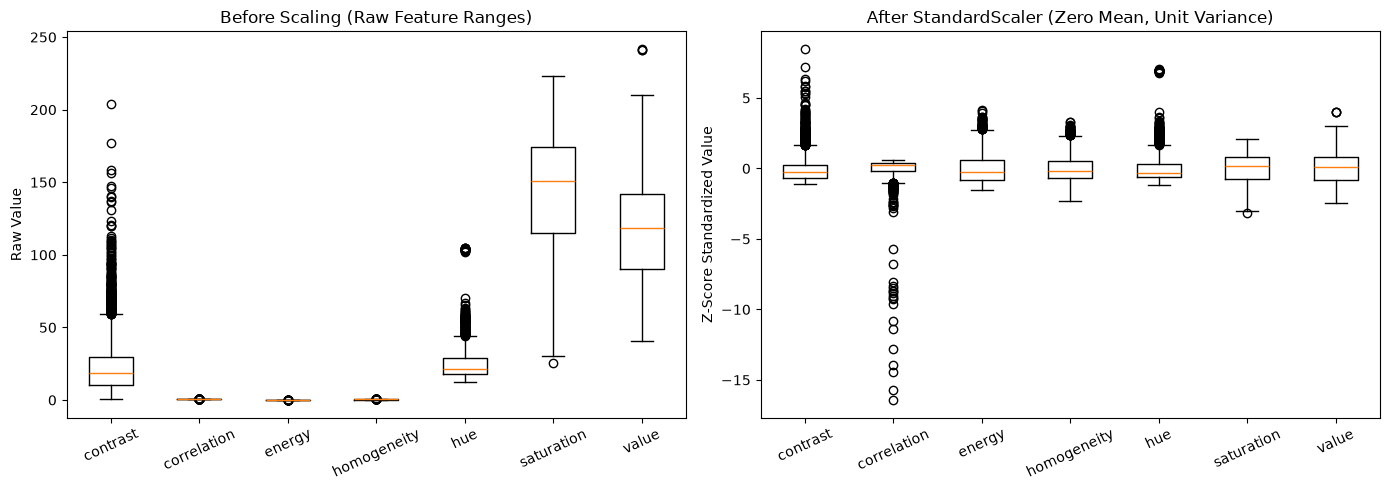

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].boxplot(X, tick_labels=feature_cols)
axes[0].set_title("Before Scaling (Raw Feature Ranges)")
axes[0].set_ylabel("Raw Value")
axes[0].tick_params(axis="x", rotation=25)

axes[1].boxplot(X_scaled, tick_labels=feature_cols)
axes[1].set_title("After StandardScaler (Zero Mean, Unit Variance)")
axes[1].set_ylabel("Z-Score Standardized Value")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()